# 何が市区町村の女性の労働力率を左右しているか

- データ：政府統計の総合窓口(e-Stat) 社会・人口統計体系（市区町村データ）。取得手順は README を参照
- 目的変数：女性の労働力率＝労働力人口（女）÷（労働力人口（女）＋非労働力人口（女））、2020年国勢調査
- 方法：標準化した重回帰（OLS、HC3 頑健標準誤差）。都道府県の固定効果あり／なしを比べる
- **注意**：市区町村単位の観察データなので、結果は「関係」であって「原因」ではありません

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset, analysis
build_dataset.main()

(1741, 95) count    1740.000000
mean        0.516423
std         0.052570
min         0.320341
25%         0.486072
50%         0.519233
75%         0.547603
max         0.827586
Name: y_flfp, dtype: float64


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


## 1. データを見る

In [2]:
import pandas as pd, numpy as np
d = analysis.load()
print(len(d), "市区町村")
d[["y_flfp"] + analysis.X].describe().T.round(3)

1739 市区町村


,count,mean,std,min,25%,50%,75%,max
y_flfp,1739.0,0.516,0.053,0.320,0.486,0.519,0.548,0.828
w_old_share,1739.0,0.428,0.085,0.172,0.365,0.427,0.487,0.709
primary_share,1739.0,0.103,0.099,0.000,0.027,0.073,0.150,0.756
nuclear_share,1739.0,0.554,0.063,0.176,0.519,0.555,0.593,0.759
child_share,1739.0,0.039,0.011,0.007,0.032,0.039,0.046,0.085
childcare_per_child,1739.0,0.690,0.371,0.000,0.425,0.631,0.899,2.868
log_density,1739.0,6.253,1.380,2.236,5.404,6.153,7.092,10.051
log_income,1739.0,1.182,0.160,0.895,1.078,1.157,1.252,2.880
w_commute_out,1739.0,0.333,0.180,0.000,0.178,0.347,0.486,0.775
univ_share,1739.0,0.150,0.068,0.035,0.102,0.133,0.183,0.478


In [3]:
d[["y_flfp"] + analysis.X].corr()["y_flfp"].sort_values().round(2)

w_old_share           -0.67
childcare_per_child   -0.17
nuclear_share         -0.10
tertiary_share        -0.05
primary_share          0.01
w_commute_out          0.08
log_density            0.19
log_income             0.33
univ_share             0.33
child_share            0.59
y_flfp                 1.00
Name: y_flfp, dtype: float64

## 2. 回帰と頑健性チェック（図も作成）

In [4]:
analysis.main()

市区町村数: 1739


R2  年齢だけ=0.444  都道府県だけ=0.217  10変数=0.718  10変数+都道府県=0.797
                                     変数  係数_都道府県なし  p_都道府県なし  係数_都道府県あり  95%下限  95%上限  p_都道府県あり
w_old_share                 65歳以上の女性の割合     -0.955     0.000     -1.112 -1.198 -1.027     0.000
nuclear_share                  核家族世帯の割合     -0.242     0.000     -0.205 -0.250 -0.160     0.000
log_density                人口密度（可住地、対数）     -0.054     0.187     -0.190 -0.280 -0.101     0.000
log_income               納税者1人あたり所得（対数）     -0.194     0.000     -0.140 -0.205 -0.075     0.000
w_commute_out        女性で他の市区町村へ通勤する人の割合     -0.042     0.011     -0.067 -0.101 -0.033     0.000
univ_share                   大学・大学院卒の割合      0.194     0.000     -0.060 -0.134  0.015     0.115
tertiary_share             第3次産業で働く人の割合     -0.158     0.000      0.037 -0.025  0.099     0.238
childcare_per_child   保育所・こども園に通う子どもの割合      0.102     0.000      0.071  0.036  0.106     0.000
child_share                 0〜5歳の子どもの割合      0.125     0.000      0.109  0.046

               チェック     n w_old_share primary_share nuclear_share childcare_per_child log_income log_density nursery_per_1k_child
0       基本（都道府県を固定）  1739      -1.11*        +0.47*        -0.21*              +0.07*     -0.14*      -0.19*                  NaN
1     都道府県でまとめた標準誤差  1739      -1.11*        +0.47*        -0.21*              +0.07*     -0.14*      -0.19*                  NaN
2           人口で重みづけ  1739      -0.98*        +0.50*        -0.27*              +0.11*      -0.02       -0.02                  NaN
3      人口5,000人以上だけ  1450      -1.15*        +0.46*        -0.21*              +0.06*     -0.08*      -0.14*                  NaN
4          東京23区を除く  1716      -1.11*        +0.47*        -0.18*              +0.07*     -0.18*      -0.20*                  NaN
5  保育を施設数(2023)に替える  1739      -1.13*        +0.46*        -0.20*                 NaN     -0.14*      -0.19*                +0.04


    pref_name  name    y_flfp
687       東京都  青ヶ島村  0.827586
681       東京都   利島村  0.796296
685       東京都  御蔵島村  0.779661
751       新潟県  粟島浦村  0.768707
688       東京都  小笠原村  0.737460
    pref_name  name    y_flfp
490       群馬県   神流町  0.320341
405       福島県   飯舘村  0.331081
492       群馬県   南牧村  0.335731
378       福島県   金山町  0.337691
26        北海道  歌志内市  0.342502
pref top/bottom {'富山県': 2.36, '鳥取県': 2.43, '宮崎県': 3.1, '福井県': 3.2, '長野県': 3.82} {'奈良県': -5.05, '大阪府': -4.46, '山口県': -2.8, '神奈川県': -2.7, '福岡県': -2.4}
SD {'w_old_share': 0.0852, 'primary_share': 0.0986, 'nuclear_share': 0.0632, 'child_share': 0.0106, 'childcare_per_child': 0.3714, 'log_density': 1.38, 'log_income': 0.16, 'w_commute_out': 0.1801, 'univ_share': 0.068, 'tertiary_share': 0.0961, 'y_flfp': 0.0526}


## 3. 図

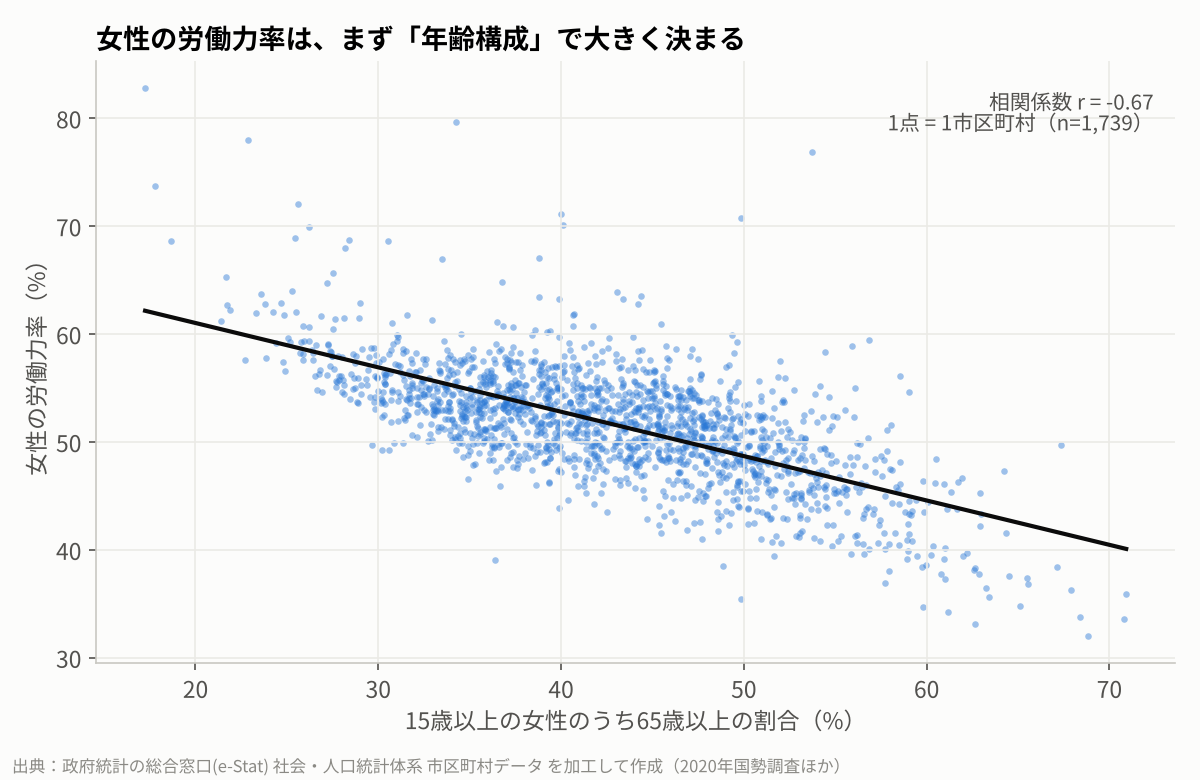

In [5]:
from IPython.display import Image
Image(str(ROOT / 'figures' / 'fig1_age_vs_flfp.png'))

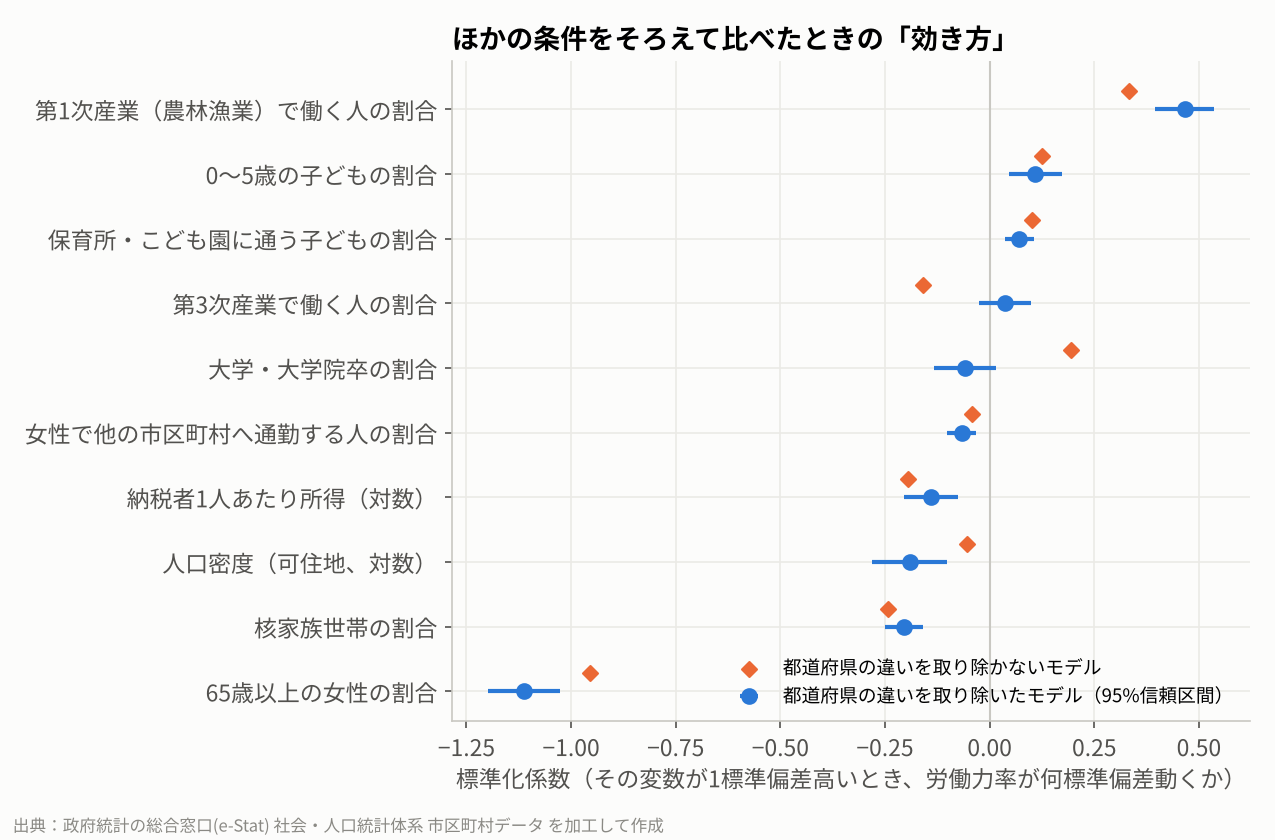

In [6]:
from IPython.display import Image
Image(str(ROOT / 'figures' / 'fig2_coefficients.png'))

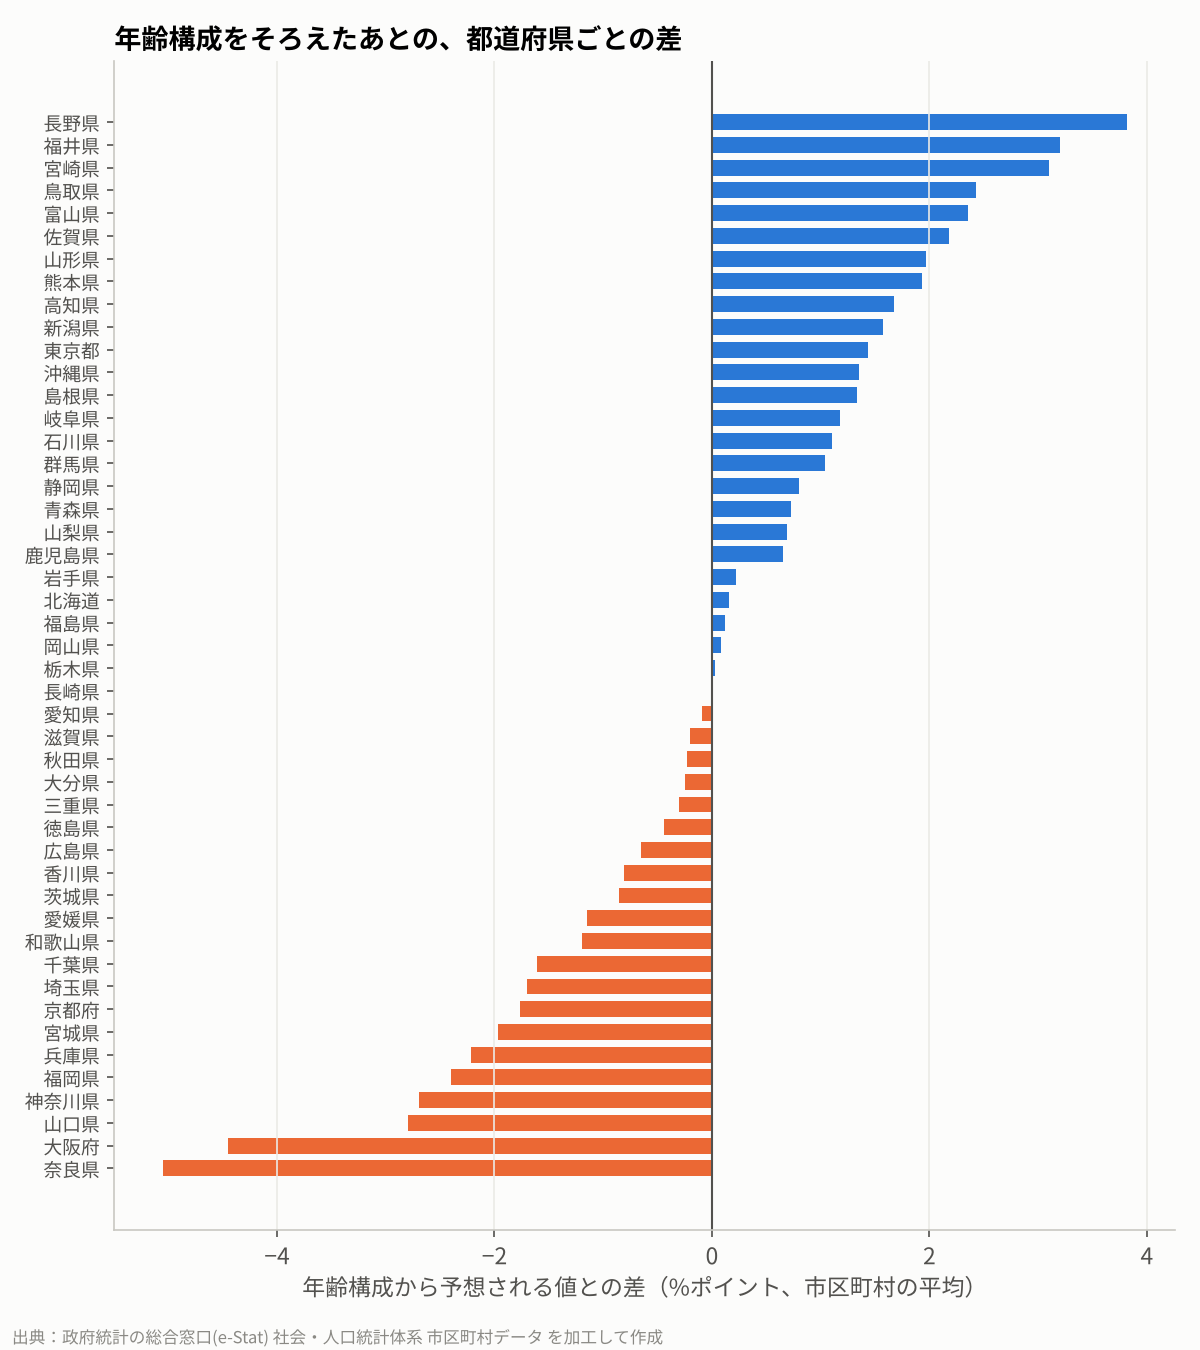

In [7]:
from IPython.display import Image
Image(str(ROOT / 'figures' / 'fig3_pref_residual.png'))

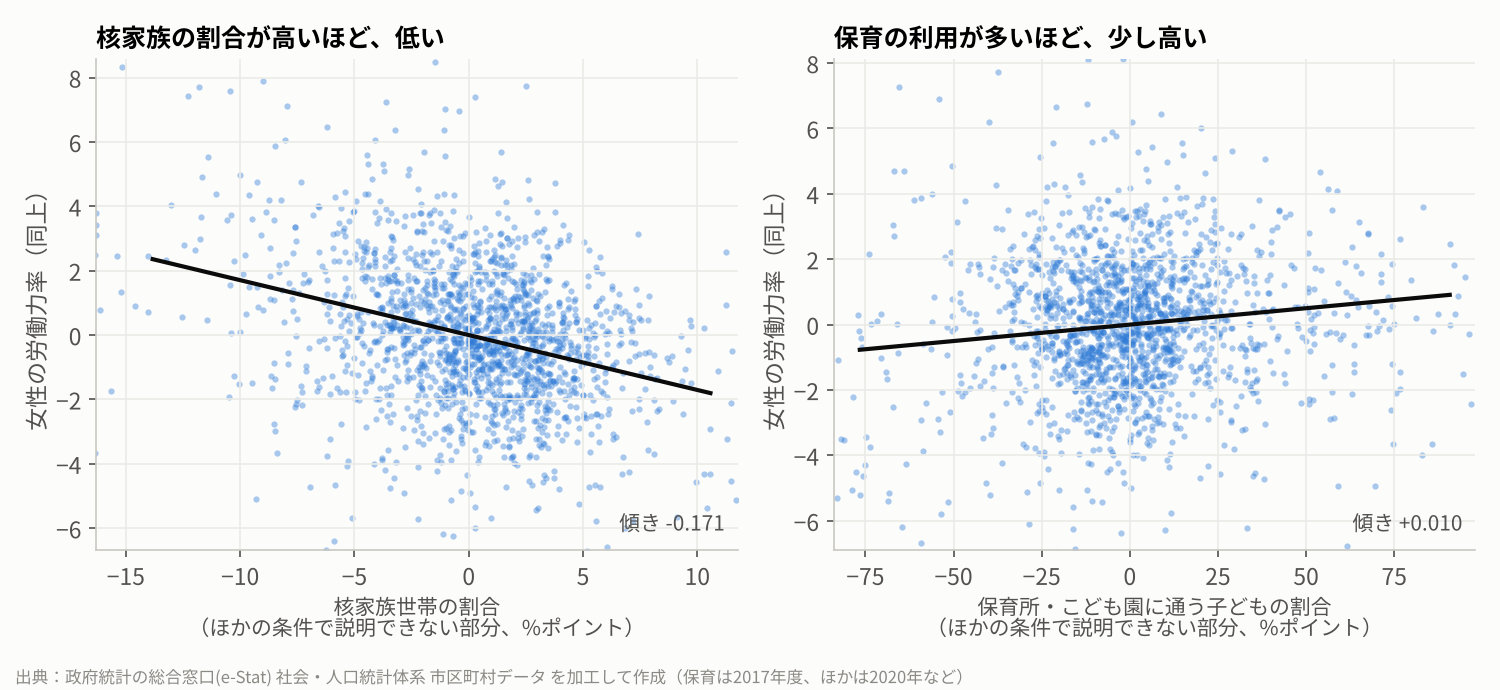

In [8]:
from IPython.display import Image
Image(str(ROOT / 'figures' / 'fig4_partial_nuclear_childcare.png'))

## 4. 読み方と限界

- 一番効いているのは年齢構成（65歳以上の女性の割合）。年齢だけで分散の約44%を説明する
- 年齢をそろえても、農林漁業の割合（＋）、核家族の割合（−）、保育の利用（小さな＋）は、都道府県をそろえても・重みを変えても残る
- 所得（−）と人口密度（−）は、人口で重みづけすると消えるので、強くは言えない
- 限界：生態学的誤謬（市区町村の関係が個人に当てはまるとは限らない）、逆の因果（働く女性が多い所で保育が増える）、年のずれ（保育は2017年度）、観測していない要因（通勤時間、職場の制度、地域の慣習など）